# Problem 1: Trajectory Optimization

In this problem you will compute a trajectory for the unicycle that reaches a goal pose while avoiding a circular obstacle, by transcribing the optimal control problem into a nonlinear program and solving it with `scipy.optimize.minimize`.

All of your code goes in `P1_trajopt.py`. This notebook only runs and plots it.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import matplotlib.pyplot as plt

from P1_trajopt import *

os.makedirs("plots", exist_ok=True)

## Visualizing the Scene
Green is the start, red is the goal, and blue is the obstacle.

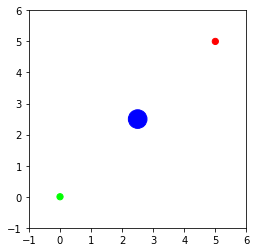

In [2]:
def render_scene(s=None, title=None, ax=None):
    if ax is None:
        fig, ax = plt.subplots()
    ax.add_patch(plt.Circle(OBS_POS, radius=OBS_RADIUS, color='blue'))
    if s is not None:
        for x, y, th in s:
            ax.add_patch(plt.Circle((x, y), radius=EGO_RADIUS, color='cyan'))
            ax.arrow(x, y, dx=np.cos(th) / 2, dy=np.sin(th) / 2, head_width=0.1)
    ax.add_patch(plt.Circle(S_0[:2], radius=EGO_RADIUS, color='lime'))
    ax.add_patch(plt.Circle(S_F[:2], radius=EGO_RADIUS, color='red'))
    ax.set_xlim((-1.0, 6.0))
    ax.set_ylim((-1.0, 6.0))
    ax.set_aspect('equal')
    if title is not None:
        ax.set_title(title)
    return ax

render_scene()
plt.show()

## Sanity Checks
Run this cell after implementing `cost`, `dynamics_constraints`, `boundary_constraints`, and `obstacle_constraints`. It only checks a few simple cases; passing it does not guarantee full credit.

In [3]:
# A trajectory driving straight up the y axis at V = 0.5 with om = 0 is dynamically feasible
t_f = 10.0
dt = t_f / N
s = np.zeros((N + 1, s_dim))
s[:, 1] = 0.5 * dt * np.arange(N + 1)
s[:, 2] = np.pi / 2
u = np.tile([0.5, 0.0], (N, 1))
z = pack_decision_variables(t_f, s, u)

assert np.isclose(cost(z, 2.0), 2.0 * 10.0 + 10.0 * 0.25)
assert dynamics_constraints(z).shape == (N, s_dim)
assert np.allclose(dynamics_constraints(z), 0.0)
assert boundary_constraints(z, S_0, S_F).shape == (2, s_dim)
assert np.allclose(boundary_constraints(z, S_0, S_F)[0], 0.0)
assert np.allclose(boundary_constraints(z, S_0, S_F)[1], [-5.0, 0.0, 0.0])
assert obstacle_constraints(z, OBS_POS, OBS_RADIUS, EGO_RADIUS).shape == (N + 1,)
assert np.isclose(obstacle_constraints(z, OBS_POS, OBS_RADIUS, EGO_RADIUS)[0], np.sqrt(2) * 2.5 - 0.4)
print("Sanity checks passed")

Sanity checks passed


## Trajectory Optimization
Solve the problem with $\alpha = 1$. This takes a few seconds.

Optimization terminated successfully
t_f = 14.652 s


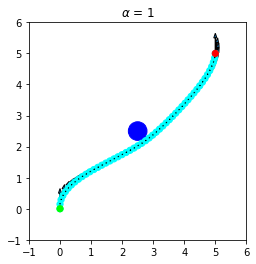

In [4]:
t_f, s, u = optimize_trajectory(alpha=1.0, verbose=True)
print(f"t_f = {t_f:.3f} s")

render_scene(s, title=r"$\alpha$ = 1")
plt.savefig("plots/p1_alpha_1.png", bbox_inches="tight")
plt.show()

## Cruising Speed vs. $\alpha$
For each value of $\alpha$ below, the cell prints the final time, the path length, and the median commanded speed over the trajectory. Use it for part (iii).

 alpha |   t_f   | length | median V
  0.04 |  39.613 |  7.318 | 0.198
  0.09 |  26.399 |  7.318 | 0.296
  0.25 |  15.847 |  7.318 | 0.494
  1.00 |  14.652 |  7.326 | 0.500


/home/jacob_goldberg/.local/lib/python3.10/site-packages/scipy/optimize/_slsqp_py.py:435: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
/home/jacob_goldberg/.local/lib/python3.10/site-packages/scipy/optimize/_slsqp_py.py:439: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  g = append(wrapped_grad(x), 0.0)
/home/jacob_goldberg/.local/lib/python3.10/site-packages/scipy/optimize/_slsqp_py.py:493: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  a_eq = vstack([con['jac'](x, *con['args'])
/home/jacob_goldberg/.local/lib/python3.10/site-packages/scipy/optimize/_slsqp_py.py:499: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  a_ieq = vstack([con['jac'](x, *con['args'])


 20.00 |  14.404 |  7.202 | 0.500


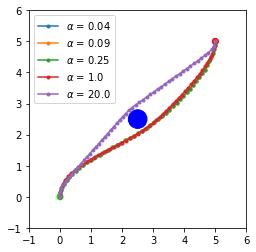

In [5]:
alphas = [0.04, 0.09, 0.25, 1.0, 20.0]

fig, ax = plt.subplots()
render_scene(ax=ax)
print(" alpha |   t_f   | length | median V")
for alpha in alphas:
    t_f, s, u = optimize_trajectory(alpha=alpha)
    length = np.sum(np.linalg.norm(np.diff(s[:, :2], axis=0), axis=1))
    print(f"{alpha:6.2f} | {t_f:7.3f} | {length:6.3f} | {np.median(u[:, 0]):.3f}")
    ax.plot(s[:, 0], s[:, 1], '.-', label=rf"$\alpha$ = {alpha}")
ax.legend()
plt.savefig("plots/p1_alpha_sweep.png", bbox_inches="tight")
plt.show()